# BIM-based Project Workflows with IfcOpenShell

**Goal:** Learn to read a BIM model not only as geometry, but through its **objects**, **parameters**, **classifications**, and **relationships**.

This notebook is designed for Google Colab and shows the skills nedded for many openBIM / digital construction related analytics and design.

**What you will practice:**
1. Load an IFC model
2. Explore objects (walls, doors, spaces, slabs…)
3. Extract parameters / property sets
4. Inspect classifications
5. Walk relationships and spatial structure
6. **Visualize** the model data (charts)
7. Export useful tables with pandas

---
Author GitHub [S33mi](https://github.com/S33mi)

## 1. Install dependencies

In [21]:
!pip install -q ifcopenshell pandas matplotlib seaborn

import ifcopenshell
import ifcopenshell.util.element
import ifcopenshell.util.placement
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import requests
from pathlib import Path

# Nice default style for charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

print("IfcOpenShell version:", ifcopenshell.version)

IfcOpenShell version: 0.9.0


## 2. Download a free sample BIM model

We use the classic **FZK House** (Karlsruhe Institute of Technology).  
It is small, well-known, and contains walls, doors, windows, spaces, and property data.

In [22]:
SAMPLE_URL = "https://www.ifcwiki.org/images/e/e3/AC20-FZK-Haus.ifc"
MODEL_PATH = Path("AC20-FZK-Haus.ifc")

if not MODEL_PATH.exists():
    print("Downloading sample model...")
    r = requests.get(SAMPLE_URL, timeout=60)
    r.raise_for_status()
    MODEL_PATH.write_bytes(r.content)
    print(f"Saved → {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
else:
    print("Model already exists:", MODEL_PATH)

model = ifcopenshell.open(str(MODEL_PATH))
print("Schema:", model.schema)
print("Project name:", model.by_type("IfcProject")[0].Name)

walls = model.by_type("IfcWall")
print(len(walls))

wall = walls[0]
print(wall.Name)
print(wall.GlobalId)

# Properties / parameters (this is the important part)
psets = ifcopenshell.util.element.get_psets(wall)
print(psets)

# Relationships
print(wall.IsDefinedBy)                # property sets linked to it
print(model.get_inverse(wall))         # everything that references this wall

Model already exists: AC20-FZK-Haus.ifc
Schema: IFC4
Project name: Projekt-FZK-Haus
13
Wand-Int-ERDG-4
2XPyKWY018sA1ygZKgQPtU
{'Pset_WallCommon': {'ThermalTransmittance': 1.5, 'id': 15079}, 'AC_Pset_Name': {'Name': 'Wand-Int-ERDG-4', 'id': 15087}, 'ArchiCADProperties': {'Komplette Element-ID': 'Wand-Int-ERDG-4', 'Kompakte Element-ID': 'Wand-Int-ERDG-4', 'Name des Sachmerkmal-Objekts': '', 'Ursprungsgeschoss': 'Erdgeschoss', 'Raumname': 'Wohnen', 'Raumnummer': '5', 'Ebene': 'Innenwände', 'Typ': 'Wand', 'Geschützt': False, 'Baustoff / Mehrschichtiger Aufbau / Profil / Schraffur': 'Leichtbeton 102890359', 'Etikettentext': '', 'Eindeutige ID': 'BC6F0F70-6195-495E-A2FC-239713029DB1', 'Verknüpfte Änderungen': '', 'Tragende Funktion': 'Nicht definiert', 'Lage': 'Nicht definiert', 'Element-Klassifizierung': 'Wand', 'Umbau-Status': 'Bestand', 'Anzeigen auf Umbau-Filter': 'Alle relevanten Filter', 'Struktur - Typ': 'Einfach', 'ARCHICAD IFC ID': '2XPyKWY018sA1ygZKgQPtU', 'Externe IFC ID': '', 'Ba

## 3. Objects – what is inside the model?

A BIM model is a collection of **entities**. The most interesting ones for project workflows are the building elements.

In [23]:
# Count main building elements
interesting_types = [
    "IfcWall", "IfcWallStandardCase", "IfcSlab", "IfcRoof",
    "IfcDoor", "IfcWindow", "IfcColumn", "IfcBeam",
    "IfcSpace", "IfcBuildingStorey", "IfcBuilding", "IfcSite"
]

counts = {}
for t in interesting_types:
    counts[t] = len(model.by_type(t))

df_counts = pd.DataFrame(
    [{"IFC Class": k, "Count": v} for k, v in counts.items() if v > 0]
).sort_values("Count", ascending=False)

print("Main objects in the model:")
display(df_counts)

Main objects in the model:


,IFC Class,Count
0,IfcWall,13
1,IfcWallStandardCase,13
4,IfcWindow,11
6,IfcSpace,7
3,IfcDoor,5
2,IfcSlab,4
5,IfcBeam,4
7,IfcBuildingStorey,2
8,IfcBuilding,1
9,IfcSite,1


In [24]:
# Peek at a few walls
walls = model.by_type("IfcWall") + model.by_type("IfcWallStandardCase")
print(f"Total walls: {len(walls)}\n")

for wall in walls[:5]:
    print(f"• {wall.is_a()} | Name: {wall.Name!r} | GlobalId: {wall.GlobalId}")

Total walls: 26

• IfcWallStandardCase | Name: 'Wand-Int-ERDG-4' | GlobalId: 2XPyKWY018sA1ygZKgQPtU
• IfcWallStandardCase | Name: 'Wand-Int-ERDG-2' | GlobalId: 3PfS__Y_DBAfq5naM6zD2Z
• IfcWallStandardCase | Name: 'Wand-Int-ERDG-1' | GlobalId: 2ptk1k7qn8_Qk22vjh$0DE
• IfcWallStandardCase | Name: 'Wand-Int-ERDG-3' | GlobalId: 3jjW3rL656ex34Gws22EfM
• IfcWallStandardCase | Name: 'Wand-Int-ERDG-5' | GlobalId: 1$wmdwWPjDYuku_ghVkynE


## 4. Parameters / Property Sets

This is the core skill for **reading data attached to objects**, not just geometry.

`ifcopenshell.util.element.get_psets()` returns all property sets and quantities.

In [25]:
wall = walls[0]
print("Examining wall:", wall.Name, "|", wall.GlobalId)
print("-" * 60)

psets = ifcopenshell.util.element.get_psets(wall)

for pset_name, props in psets.items():
    print(f"\n📦 Property Set: {pset_name}")
    for key, value in props.items():
        if key == "id":
            continue
        print(f"   {key}: {value}")

Examining wall: Wand-Int-ERDG-4 | 2XPyKWY018sA1ygZKgQPtU
------------------------------------------------------------

📦 Property Set: Pset_WallCommon
   ThermalTransmittance: 1.5

📦 Property Set: AC_Pset_Name
   Name: Wand-Int-ERDG-4

📦 Property Set: ArchiCADProperties
   Komplette Element-ID: Wand-Int-ERDG-4
   Kompakte Element-ID: Wand-Int-ERDG-4
   Name des Sachmerkmal-Objekts: 
   Ursprungsgeschoss: Erdgeschoss
   Raumname: Wohnen
   Raumnummer: 5
   Ebene: Innenwände
   Typ: Wand
   Geschützt: False
   Baustoff / Mehrschichtiger Aufbau / Profil / Schraffur: Leichtbeton 102890359
   Etikettentext: 
   Eindeutige ID: BC6F0F70-6195-495E-A2FC-239713029DB1
   Verknüpfte Änderungen: 
   Tragende Funktion: Nicht definiert
   Lage: Nicht definiert
   Element-Klassifizierung: Wand
   Umbau-Status: Bestand
   Anzeigen auf Umbau-Filter: Alle relevanten Filter
   Struktur - Typ: Einfach
   ARCHICAD IFC ID: 2XPyKWY018sA1ygZKgQPtU
   Externe IFC ID: 
   Baustoff/Mehrschicht/Profil: Leichtbeton

In [26]:
# Build a table of walls + a few common properties
rows = []
for w in walls:
    psets = ifcopenshell.util.element.get_psets(w)
    # Flatten common psets if they exist
    common = psets.get("Pset_WallCommon", {})
    qto = psets.get("Qto_WallBaseQuantities", {}) or psets.get("BaseQuantities", {})

    rows.append({
        "GlobalId": w.GlobalId,
        "Name": w.Name,
        "Type": w.is_a(),
        "IsExternal": common.get("IsExternal"),
        "LoadBearing": common.get("LoadBearing"),
        "FireRating": common.get("FireRating"),
        "ThermalTransmittance": common.get("ThermalTransmittance"),
        "NetSideArea": qto.get("NetSideArea") or qto.get("GrossSideArea"),
        "Height": qto.get("Height"),
        "Length": qto.get("Length"),
    })

df_walls = pd.DataFrame(rows)
print(f"Walls table ({len(df_walls)} rows):")
display(df_walls.head(10))

Walls table (26 rows):


,GlobalId,Name,Type,IsExternal,LoadBearing,FireRating,ThermalTransmittance,NetSideArea,Height,Length
0,2XPyKWY018sA1ygZKgQPtU,Wand-Int-ERDG-4,IfcWallStandardCase,None,None,None,1.5,10.425000,2.500000,4.17
1,3PfS__Y_DBAfq5naM6zD2Z,Wand-Int-ERDG-2,IfcWallStandardCase,None,None,None,1.5,11.822150,2.500000,5.57
2,2ptk1k7qn8_Qk22vjh$0DE,Wand-Int-ERDG-1,IfcWallStandardCase,None,None,None,1.5,9.275000,2.500000,3.71
3,3jjW3rL656ex34Gws22EfM,Wand-Int-ERDG-3,IfcWallStandardCase,None,None,None,1.5,13.917300,2.500000,7.11
4,1$wmdwWPjDYuku_ghVkynE,Wand-Int-ERDG-5,IfcWallStandardCase,None,None,None,1.5,8.750000,2.500000,3.50
5,3rPX_Juz59peXXY6wDJl18,Wand-Ext-ERDG-1,IfcWallStandardCase,None,None,None,0.4,18.759900,2.700000,9.70
6,16DNNqzfP2thtfaOflvsKA,Wand-Ext-ERDG-4,IfcWallStandardCase,None,None,None,0.4,22.016250,2.700000,11.70
7,25fsbPyk15VvuXI$yNKenK,Wand-Ext-ERDG-3,IfcWallStandardCase,None,None,None,0.4,21.090000,2.700000,9.70
8,1bzfVsJqn8De5PukCrqylz,Wand-Ext-ERDG-2,IfcWallStandardCase,None,None,None,0.4,23.790000,2.700000,11.70
9,0knNIAVBPBFvBy_m5QVHsU,Wand-Ext-OG-1,IfcWallStandardCase,None,None,None,0.4,18.472693,3.386751,9.70


## 5. Classifications

Classifications (Uniclass, OmniClass, CCI, national systems, etc.) are stored as `IfcClassificationReference` linked to elements.

Not every model has rich classifications – the FZK House is relatively light – but the pattern is the same on real project models.

In [27]:
def get_classifications(element):
    """Return list of classification references for an element."""
    results = []
    for rel in getattr(element, "HasAssociations", []) or []:
        if rel.is_a("IfcRelAssociatesClassification"):
            ref = rel.RelatingClassification
            if ref.is_a("IfcClassificationReference"):
                results.append({
                    "Identification": getattr(ref, "Identification", None),
                    "Name": getattr(ref, "Name", None),
                    "Location": getattr(ref, "Location", None),
                    "ReferencedSource": getattr(getattr(ref, "ReferencedSource", None), "Name", None),
                })
            elif ref.is_a("IfcClassification"):
                results.append({"Name": ref.Name, "Source": getattr(ref, "Source", None)})
    return results

# Check a few walls for classifications
classified = 0
for w in walls[:20]:
    cls = get_classifications(w)
    if cls:
        classified += 1
        print(w.Name, "→", cls)

if classified == 0:
    print("No IfcClassificationReference found on the first 20 walls of this sample model.")
    print("On real project models you will usually see Uniclass / OmniClass codes here.")
    print("\nPattern to remember:")
    print("  element.HasAssociations → IfcRelAssociatesClassification → IfcClassificationReference")

No IfcClassificationReference found on the first 20 walls of this sample model.
On real project models you will usually see Uniclass / OmniClass codes here.

Pattern to remember:
  element.HasAssociations → IfcRelAssociatesClassification → IfcClassificationReference


## 6. Relationships & Spatial Structure

Key relationships for project workflows:
- **Spatial containment** (Project → Site → Building → Storey → Space / Element)
- Aggregations
- Openings (voids)
- Connections
- Type relationships

In [28]:
# Spatial hierarchy
print("=== SPATIAL STRUCTURE ===\n")

project = model.by_type("IfcProject")[0]
print(f"Project: {project.Name}")

for site in model.by_type("IfcSite"):
    print(f"  Site: {site.Name}")

for building in model.by_type("IfcBuilding"):
    print(f"    Building: {building.Name}")

storeys = model.by_type("IfcBuildingStorey")
for storey in sorted(storeys, key=lambda s: s.Elevation or 0):
    print(f"      Storey: {storey.Name}  (Elevation: {storey.Elevation})")

=== SPATIAL STRUCTURE ===

Project: Projekt-FZK-Haus
  Site: Gelaende
    Building: FZK-Haus
      Storey: Erdgeschoss  (Elevation: 0.0)
      Storey: Dachgeschoss  (Elevation: 2.7)


In [29]:
# Which storey does each wall belong to?
def get_containing_storey(element):
    """Walk spatial containment to find the storey."""
    container = ifcopenshell.util.element.get_container(element)
    while container:
        if container.is_a("IfcBuildingStorey"):
            return container
        container = ifcopenshell.util.element.get_container(container)
    return None

storey_counts = Counter()
storey_for_wall = []
for w in walls:
    storey = get_containing_storey(w)
    name = storey.Name if storey else "Unknown"
    storey_counts[name] += 1
    storey_for_wall.append(name)

df_walls["Storey"] = storey_for_wall

print("Walls per storey:")
for name, count in storey_counts.most_common():
    print(f"  {name}: {count}")

Walls per storey:
  Erdgeschoss: 18
  Dachgeschoss: 8


In [30]:
# Openings (voids) in walls – a classic relationship
print("=== OPENINGS IN WALLS ===\n")

opening_count = 0
openings_per_wall = []
for wall in walls:
    n = 0
    for rel in getattr(wall, "HasOpenings", []) or []:
        if rel.is_a("IfcRelVoidsElement"):
            n += 1
            opening_count += 1
    openings_per_wall.append(n)

df_walls["Openings"] = openings_per_wall
print(f"Total openings found: {opening_count}")
print(f"Walls with at least one opening: {(df_walls['Openings'] > 0).sum()}")

=== OPENINGS IN WALLS ===

Total openings found: 32
Walls with at least one opening: 16


## 7. Spaces (rooms) – another important object type

In [31]:
spaces = model.by_type("IfcSpace")
print(f"Number of spaces: {len(spaces)}\n")

space_rows = []
for space in spaces:
    psets = ifcopenshell.util.element.get_psets(space)
    qto = psets.get("Qto_SpaceBaseQuantities", {}) or {}
    common = psets.get("Pset_SpaceCommon", {}) or {}

    space_rows.append({
        "Name": space.Name,
        "LongName": space.LongName,
        "GlobalId": space.GlobalId,
        "NetFloorArea": qto.get("NetFloorArea") or qto.get("GrossFloorArea"),
        "Height": qto.get("Height"),
        "IsExternal": common.get("IsExternal"),
    })

df_spaces = pd.DataFrame(space_rows)
display(df_spaces)

Number of spaces: 7



,Name,LongName,GlobalId,NetFloorArea,Height,IsExternal
0,4,Schlafzimmer,347jFE2yX7IhCEIALmupEH,None,None,None
1,3,Bad,0e_hbkIQ5DMQlIJ$2V3j_m,None,None,None
2,2,Buero,2RSCzLOBz4FAK$_wE8VckM,None,None,None
3,5,Wohnen,0Lt8gR_E9ESeGH5uY_g9e9,None,None,None
4,1,Flur,3$f2p7VyLB7eox67SA_zKE,None,None,None
5,6,Küche,17JZcMFrf5tOftUTidA0d3,None,None,None
6,7,Galerie,2dQFggKBb1fOc1CqZDIDlx,None,None,None


## 8. Visualization – turn BIM data into charts

##  Chart 1: Object counts by IFC class

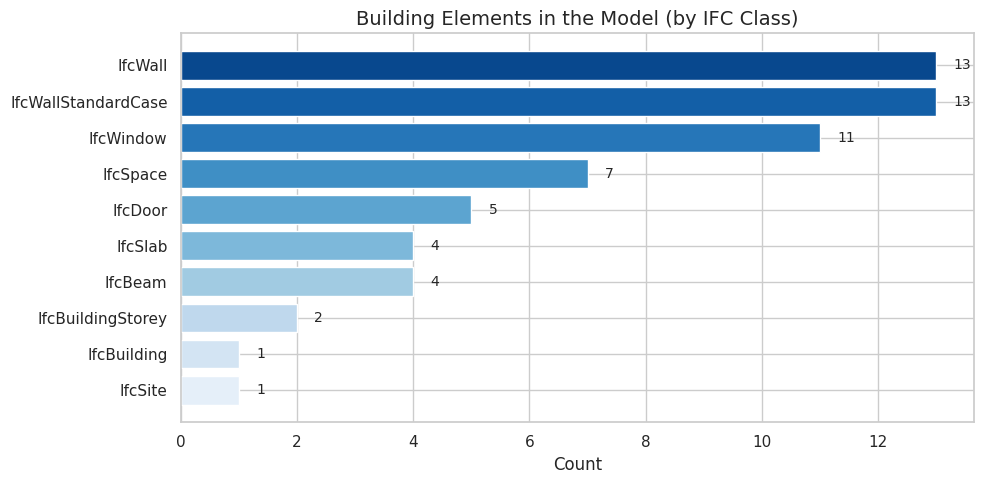

In [32]:
# Chart 1: Object counts by IFC class
fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette("Blues_r", n_colors=len(df_counts))
bars = ax.barh(df_counts["IFC Class"], df_counts["Count"], color=colors)
ax.set_xlabel("Count")
ax.set_title("Building Elements in the Model (by IFC Class)")
ax.invert_yaxis()

# Add value labels
for bar, val in zip(bars, df_counts["Count"]):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, str(val),
            va="center", fontsize=10)

plt.tight_layout()
plt.show()

## Chart 2: Walls per storey

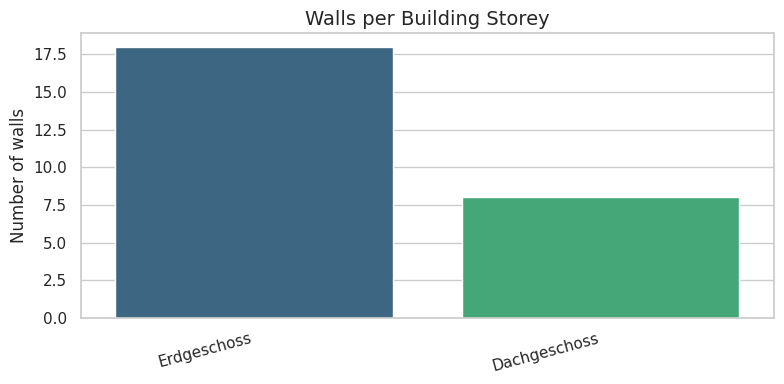

In [33]:
# Chart 2: Walls per storey
storey_df = (
    df_walls["Storey"]
    .value_counts()
    .reset_index()
)
storey_df.columns = ["Storey", "Walls"]

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=storey_df, x="Storey", y="Walls", ax=ax, hue="Storey", legend=False, palette="viridis")
ax.set_title("Walls per Building Storey")
ax.set_ylabel("Number of walls")
ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Chart 3: External vs Internal walls

In [34]:
# Chart 3: External vs Internal walls (when the property exists)
if df_walls["IsExternal"].notna().any():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Pie chart
    ext_counts = df_walls["IsExternal"].value_counts(dropna=False)
    labels = []
    for v in ext_counts.index:
        if v is True:
            labels.append("External")
        elif v is False:
            labels.append("Internal")
        else:
            labels.append("Unknown")

    axes[0].pie(ext_counts, labels=labels, autopct="%1.0f%%",
                colors=sns.color_palette("pastel"), startangle=90)
    axes[0].set_title("Walls: External vs Internal")

    # Bar by storey + external
    tmp = df_walls.copy()
    tmp["IsExternal_label"] = tmp["IsExternal"].map({True: "External", False: "Internal"}).fillna("Unknown")
    sns.countplot(data=tmp, x="Storey", hue="IsExternal_label", ax=axes[1], palette="Set2")
    axes[1].set_title("External / Internal walls by storey")
    axes[1].set_xlabel("")
    axes[1].tick_params(axis="x", rotation=15)

    plt.tight_layout()
    plt.show()
else:
    print("IsExternal property not populated on walls in this sample model.")

IsExternal property not populated on walls in this sample model.


## Chart 4: Openings distribution

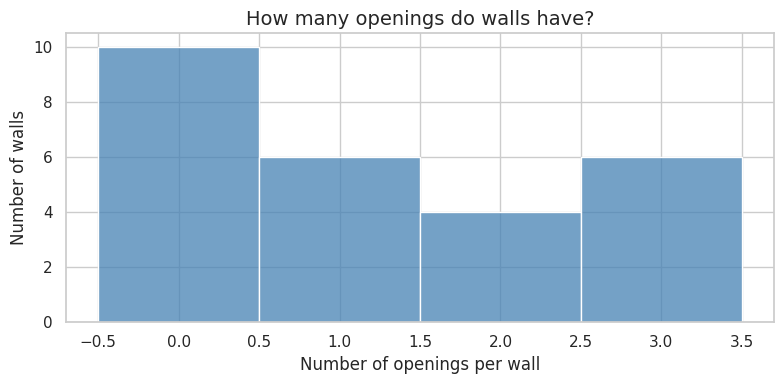

Average openings per wall: 1.23


In [35]:
# Chart 4: Openings distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_walls["Openings"], bins=range(0, df_walls["Openings"].max() + 2), discrete=True, ax=ax, color="steelblue")
ax.set_title("How many openings do walls have?")
ax.set_xlabel("Number of openings per wall")
ax.set_ylabel("Number of walls")
plt.tight_layout()
plt.show()

print(f"Average openings per wall: {df_walls['Openings'].mean():.2f}")

## Chart 5: Space areas

In [36]:
# Chart 5: Space areas (if quantities exist)
if df_spaces["NetFloorArea"].notna().any():
    plot_df = df_spaces.dropna(subset=["NetFloorArea"]).copy()
    plot_df["Label"] = plot_df["LongName"].fillna(plot_df["Name"]).astype(str)

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=plot_df.sort_values("NetFloorArea", ascending=False),
                x="NetFloorArea", y="Label", ax=ax, hue="Label", legend=False, palette="coolwarm")
    ax.set_title("Space Floor Areas")
    ax.set_xlabel("Net Floor Area")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print("No floor area quantities found on spaces in this sample.")
    print("On richer models you would see room sizes here – useful for area schedules.")

No floor area quantities found on spaces in this sample.
On richer models you would see room sizes here – useful for area schedules.


## Chart 6: Summary dashboard

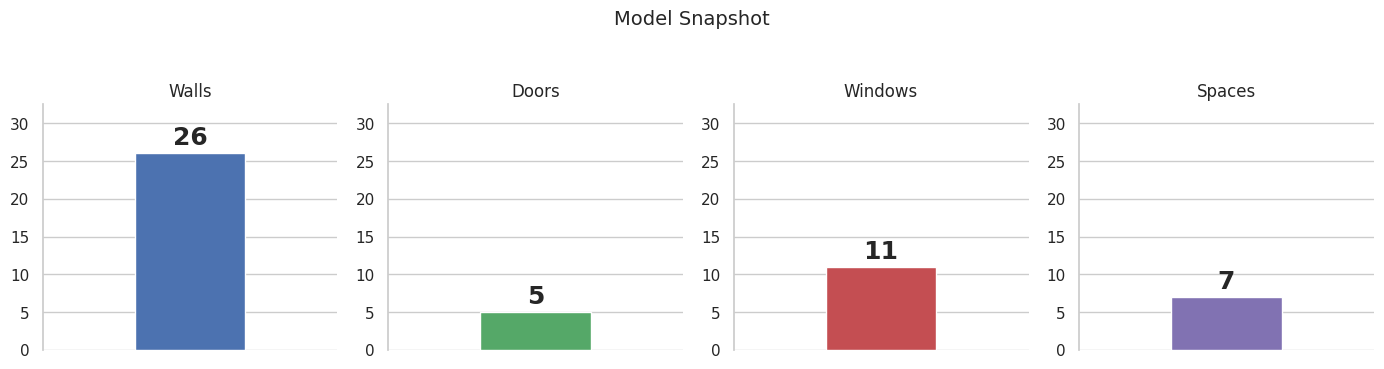

In [37]:
# Chart 6: Summary dashboard – key numbers at a glance
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

metrics = [
    ("Walls", len(walls), "#4C72B0"),
    ("Doors", len(model.by_type("IfcDoor")), "#55A868"),
    ("Windows", len(model.by_type("IfcWindow")), "#C44E52"),
    ("Spaces", len(spaces), "#8172B2"),
]

for ax, (label, value, color) in zip(axes, metrics):
    ax.bar([0], [value], color=color, width=0.6)
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(0, max(m[1] for m in metrics) * 1.25)
    ax.set_xticks([])
    ax.set_title(label, fontsize=12)
    ax.text(0, value + 0.5, str(value), ha="center", va="bottom", fontsize=18, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)

fig.suptitle("Model Snapshot", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

## 9. Quick analysis summary

In [38]:
print("=== QUICK MODEL SUMMARY ===\n")
print(f"Schema          : {model.schema}")
print(f"Walls           : {len(walls)}")
print(f"Doors           : {len(model.by_type('IfcDoor'))}")
print(f"Windows         : {len(model.by_type('IfcWindow'))}")
print(f"Spaces (rooms)  : {len(spaces)}")
print(f"Storeys         : {len(storeys)}")
print(f"Total openings  : {opening_count}")

if "IsExternal" in df_walls.columns and df_walls["IsExternal"].notna().any():
    ext = df_walls["IsExternal"].value_counts(dropna=False)
    print("\nWalls by IsExternal:")
    print(ext.to_string())

=== QUICK MODEL SUMMARY ===

Schema          : IFC4
Walls           : 26
Doors           : 5
Windows         : 11
Spaces (rooms)  : 7
Storeys         : 2
Total openings  : 32


## 10. Export results

In [39]:
df_walls.to_csv("walls_parameters.csv", index=False)
df_spaces.to_csv("spaces_summary.csv", index=False)
df_counts.to_csv("object_counts.csv", index=False)

print("Exported:")
print("  • walls_parameters.csv")
print("  • spaces_summary.csv")
print("  • object_counts.csv")
print("\nYou can download these files from the Colab file browser (left sidebar).")
print("Tip: right-click any chart → Save image to also keep the visualizations.")

Exported:
  • walls_parameters.csv
  • spaces_summary.csv
  • object_counts.csv

You can download these files from the Colab file browser (left sidebar).
Tip: right-click any chart → Save image to also keep the visualizations.


## 11. What to do next (learning path for jobs)

This notebook demonstrates BIM model not only as geometry, but also through its objects, parameters, classifications and relationships.

**Plus visualizations** that make the analysis easy to present.

**Next steps to deepen the skill:**

1. Try a bigger / different model (search “open IFC sample models” or export one from Revit / Archicad).
2. Filter elements by property (e.g. all external load-bearing walls).
3. Extract quantities and make a simple cost or area report.
4. Learn `ifcopenshell.api` to **modify** data or create simple elements.

Related Work:
1. Explore the official docs: https://docs.ifcopenshell.org/
2. Optional: try the teaching notebooks → https://github.com/jakob-beetz/ifcopenshell-notebooks

---

Happy modelling 🏗️

For contribution and insihght: [S33mi](https://github.com/S33mi)

Open to Data Science/Analytics and ML/ SI (fka AI) related opportunities